In [299]:
# --- Prompt Chaining with Feedback Workflow ---
# Pipeline: history -> achievements -> article -> refined_article
# Feedback loop: if evaluator rejects, article is re-refined (max 3 attempts)
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display, Markdown
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import BaseMessage
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

In [300]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [301]:
# loading Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [302]:
# loading Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm_3_7 = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

## **Pydantic: Validation Logic for each node**

In [303]:
# Pydantic: Validate external input
class ScientistInput(BaseModel):
    scientist: str = Field( min_length=3,max_length=100, 
    description="The name of the scientist"
    )

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value.strip()

In [304]:
# Pydantic: Validate LLM outputs
class ScientistHistoryOutput(BaseModel):
    history: str = Field(description="The history of the scientist")

class ScientistAchievementsOutput(BaseModel):
    achievements: list[str] = Field(description="Five major achievements of the scientist")

class ScientistArticleOutput(BaseModel):
    article: str = Field(description="Detailed article about the scientist")

class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined article about the scientist under 1000 words")

# Evaluator/Feedback/Critic: determines if article passes quality check
# Outputs ACCEPTED/REJECTED status with improvement feedback
class EvaluatorCritic(BaseModel):
    status: Literal["ACCEPTED", "REJECTED"] = Field(
        description="Decide if the Refined Article is acceptable or not"

    )

    feedback: str = Field(
        description="Give a constructive reason why the article is not good enougn with points for improvement"
    )

In [305]:
# Structured LLMs 
history_llm = google_llm.with_structured_output(ScientistHistoryOutput)
achievements_llm = google_llm.with_structured_output(ScientistAchievementsOutput)
article_llm = google_llm.with_structured_output(ScientistArticleOutput)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

# Evaluator/Feedback/Critic
evaluator_llm = google_llm_3_7.with_structured_output(EvaluatorCritic)

## **Define Graph State**

In [306]:
# Graph State: shared state passed between all nodes
# feedback_count tracks iterations to prevent infinite loops
class State(TypedDict):
    scientist: str 
    history: NotRequired[str]
    achievements: NotRequired[list[str]]
    article: NotRequired[str]
    refined_article: NotRequired[str] # or NotRequired[Optional[str]]

    # EvaluatorCritic
    feedback: NotRequired[str]
    accepted_rejected: NotRequired[str]
    feedback_count: NotRequired[int] # Crucial: Persist loop count in state

## **Defining the Nodes**

In [307]:
# # Defining the nodes
# def generate_history(state:State):
#     # Prompt to get the scientist's information
#     prompt = PromptTemplate.from_template(
#     "Provide a brief history of {scientist}."
#     )
#     try:
#         scientist = {"scientist": state["scientist"]}
#         history_chain = prompt | history_llm
#         response = history_chain.invoke(scientist) # or  response: ScientistHistoryOutput = history_chain.invoke(scientist)
#         history_text = response.history if response and hasattr(response, "history") else None
#     except Exception as e:
#         history_text = None
#     # Returning the response as a dictionary with the key "history"
#     # return {"history": response.content}
#     # changes to this due to structured output, we can access the history attribute directly
#     return {"history": history_text}

In [308]:
# Defining the nodes
def generate_history(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    "Provide a brief history of {scientist}."
    )
    
    scientist = {"scientist": state["scientist"]}
    history_chain = prompt | history_llm
    response = history_chain.invoke(scientist) # or  response: ScientistHistoryOutput = history_chain.invoke(scientist)

    # Returning the response as a dictionary with the key "history"
    # return {"history": response.content}
    # changes to this due to structured output, we can access the history attribute directly
    return {"history": response.history}

In [309]:
# Defining the nodes
def generate_achievements(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide 5 top achievements of {scientist} in bullet points.
    Example:
    - Achievement 1
    - Achievement 2
    - Achievement 3
    - Achievement 4
    - Achievement 5
    """
    )
    
    scientist = {"scientist": state["scientist"]}
    achievement_chain = prompt | achievements_llm
    response = achievement_chain.invoke(scientist)

    achievements_list_text = "\n".join([
        f"- {achievement}" for achievement in response.achievements
    ])
    return {"achievements": achievements_list_text}

In [310]:
# Defining the nodes
def generate_article(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide an in depth article about {scientist} based on the following information:
    History: {history}
    Achievements: {achievements}
    Final Article must be in Markdown format with different sections. For example;
    ## **Title**

    ### **History**

    ### **Achievements**

    ### **Main Contributions**

    ## **Conclusion**

    This is just an example you can modify

    You must give the article in Markdown format
    """
    )
    
    information_data = {"scientist": state["scientist"], 
                        "history": state["history"], 
                        "achievements": state["achievements"] 
                        }
    article_chain = prompt | article_llm
    response = article_chain.invoke(information_data)

    # Returning the response as a dictionary with the key "article"
    return {"article": response.article}

In [311]:
# Defining the nodes
def generate_refined_article(state:State):
    # Prompt to get the scientist's information
    # Safely retrieve 'article' using .get() to prevent KeyError
    generated_article = state.get("article", "")
    current_count = state.get("feedback_count", 0)
    
    if not generated_article:
        return {"refined_article": "Error: Article was not generated properly."}
        

    article_length = len(generated_article.split())
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
        """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
        It should be concise and clear, and should not lose the main points of the article. 
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**
        
        ## **Conclusion**

        This is just an example you can modify
        You must give the article in Markdown format
        """
        )
        refined_article_data = {"scientist": state["scientist"], "article": generated_article}
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        # Returning the response as a dictionary with the key "refined_article"
        return {"refined_article": response.refined_article,
                "feedback_count": current_count
        }
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {"refined_article": generated_article,
                "feedback_count": current_count        
        }

In [312]:
# Applies evaluator feedback to improve the rejected article
def refine_article_with_feedback(state: State):
    generated_article = state.get("article", "")
    current_count = state.get("feedback_count", 0)

    feedback_prompt = PromptTemplate.from_template(
        """Improve the refined article\n{refined_article}.\nWith the provided feedback \n{feedback}
        You must give the article in Markdown format.
        """
    )
    feedback_data = {
        "refined_article": state.get("refined_article", generated_article),
        "feedback": state["feedback"]
    }
    
    feedback_chain = feedback_prompt | refined_article_llm
    response = feedback_chain.invoke(feedback_data)
    
    refined_text = response.refined_article if (response and response.refined_article) else generated_article
    current_count+=1
    print(f"Article was rejected {current_count} time(s)!")
    return {
        "refined_article": refined_text,
        "feedback_count": current_count 
    }

In [313]:
# Evaluator node: uses structured LLM to judge article quality
def llm_evaluator(state: State):
    """Evaluation of Articles"""
    refined_text = state.get("refined_article", state.get("article", ""))
    critic = evaluator_llm.invoke([
    SystemMessage(content="""You are an expect critic of articles with 5+ years' of expereience. Kindly crtitc the given article.
    """),
    HumanMessage(content=f"refined_article: {refined_text}")
    ])
    print(f"Article was {critic.status}")
    return {
        "accepted_rejected": critic.status,
        "feedback":critic.feedback
    }

In [314]:
# Conditional edge: routes to refine node (REJECTED) or ends (ACCEPTED)
# Max 3 attempts prevents infinite loops
def route_feedback(state:State):
    """Route the refined article or end based upon the feedback from the evaluator"""
    if state.get("feedback_count", 0) >= 3:
        return "ACCEPTED"
    return state.get("accepted_rejected", "ACCEPTED")

## **Building the Graph**

In [315]:
# Builds the prompt chaining graph with feedback loop
# Adds evaluate_feedback_llm node and refine_article_with_feedback node
def build_main_graph():
    workflow = StateGraph(State)

    # Registering the nodes
    workflow.add_node("generate_history", generate_history)
    workflow.add_node("generate_achievements", generate_achievements)
    workflow.add_node("generate_article", generate_article)
    workflow.add_node("generate_refined_article", generate_refined_article)
    workflow.add_node("refine_article_with_feedback", refine_article_with_feedback)  # NEW NODE
    workflow.add_node("evaluate_feedback_llm",llm_evaluator)

    # # Set entry point
    workflow.set_entry_point("generate_history")

    # # Routing Logic
    workflow.add_edge("generate_history", "generate_achievements")
    workflow.add_edge("generate_achievements", "generate_article")
    workflow.add_edge("generate_article", "generate_refined_article")
    workflow.add_edge("generate_refined_article", "evaluate_feedback_llm")
    
    # adding the evaluation path
    workflow.add_edge("refine_article_with_feedback", "evaluate_feedback_llm")
    workflow.add_conditional_edges(
        "evaluate_feedback_llm",
        route_feedback,
        {
            "ACCEPTED": END,
            "REJECTED": "refine_article_with_feedback" # Routes directly to feedback node
        }
    )

    return workflow.compile()

In [316]:
graph = build_main_graph()

In [317]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

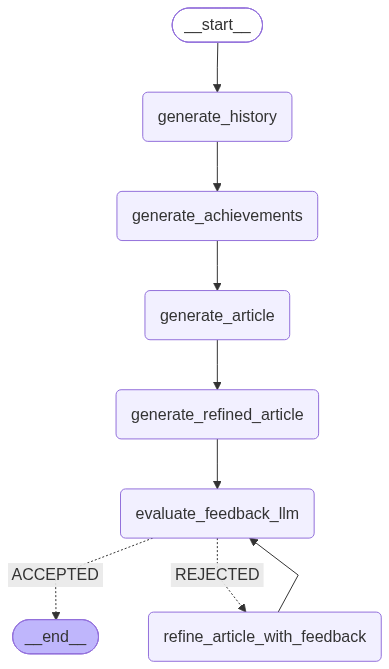

In [318]:
graph_visualiser(graph)

In [319]:
try:

    validated = ScientistInput.model_validate(
                {
                # "scientist": "Isaac Newton"
                "scientist": "Stephen William Hawking"
                # "scientist": "Banana"
                }
)

except ValidationError as e:
    print(e.errors()[0]["msg"])

In [320]:
validated

ScientistInput(scientist='Stephen William Hawking')

In [321]:
try:
    validated_wrong = ScientistInput.model_validate(
        {
            "scientist": "1234567890"
        }
    )

except ValidationError as e:
    print(e.errors()[0]["msg"])

Value error, Scientist name must contain letters.


In [322]:
# Type annotation for the initial state
intial_state: State = {
    "scientist": validated.scientist
}

results = graph.invoke(intial_state)

Initial article is already under 1000 words. No refinement needed.
Article was REJECTED
Article was rejected 1 time(s)!
Article was ACCEPTED


In [323]:
# list(results.keys())
# ['scientist',
#  'history',
#  'achievements',
#  'article',
#  'refined_article',
#  'feedback',
#  'accepted_rejected',
#  'feedback_count']

In [324]:
# Formats and displays all state fields using IPython Markdown rendering
def results_formatting(results:dict):
    """The Results formatter"""
    for key,value in results.items():
        if not isinstance(value, int):
            print(f"{key.upper()}")
            display(Markdown(value.strip()))
        else:
            print(f"{key.upper()}\n{value}\n")

In [325]:
results_formatting(results)

SCIENTIST


Stephen William Hawking

HISTORY


Stephen William Hawking (1942-2018) was a renowned British theoretical physicist and cosmologist. He made significant contributions to our understanding of black holes and the origins of the universe. Despite being diagnosed with early-onset amyotrophic lateral sclerosis (ALS) at a young age, which gradually paralyzed him, he continued his groundbreaking work for decades. His most famous works include "A Brief History of Time" and "The Universe in a Nutshell." Hawking held the position of Lucasian Professor of Mathematics at the University of Cambridge for 30 years.

ACHIEVEMENTS


...

FEEDBACK


The article is exceptionally well-structured, accurate, and engaging. It strikes an excellent balance between Hawking's biographical narrative, personal resilience, and deep theoretical contributions (Hawking Radiation, Penrose-Hawking Singularity Theorems, Hartle-Hawking State, and the Information Paradox).

Strengths:
1. Clear and professional Markdown formatting with logical progression.
2. Scientific accuracy: Key physics concepts are distilled accessibly without oversimplifying or distorting the underlying principles.
3. Engaging prose and strong synthesis of his impact as both a scientist and a public communicator.

Minor suggestions for future refinement:
- You could briefly mention his notable honors/awards (e.g., Presidential Medal of Freedom, Fundamental Physics Prize) or his cultural footprint/media cameos (e.g., Star Trek, The Simpsons) to further highlight his unique pop-culture status.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
1

